# PromptPiper — TSE paper: every figure, table and number

This notebook regenerates all content of the paper from the complete run logs in
`results/icse_26_final/` (or `$PP_RESULTS_DIR`) and runs the independent checks.
The code lives in `scripts/paper/` (one script per step, see `scripts/paper/run_all.py`);
outputs go to the paper sources (`$PP_PAPER_DIR`, default `paper/prompt_piper_paper`):
`figures/` (PDF + CSV), `tables/` (LaTeX), `numbers/` (numbers quoted in the text).

Selection rule everywhere: each optimizer's best compromise is the point of its **search-set**
front closest to (performance 1, normalised tokens 0), reported with its **test-set** values.

In [1]:
import os, subprocess, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SCRIPTS = ROOT / "scripts" / "paper"
PAPER = Path(os.environ.get("PP_PAPER_DIR", ROOT / "paper" / "prompt_piper_paper"))
FIG, TAB, NUM = PAPER / "figures", PAPER / "tables", PAPER / "numbers"

def run(script):
    r = subprocess.run([sys.executable, str(SCRIPTS / script)], capture_output=True, text=True)
    print(r.stdout[-3000:]); r.check_returncode()

def show(name):
    display(Image(filename=str(FIG / f"{name}.png")))

## Figures and statistics (all RQs)
`make_figures.py` writes every figure and the CSVs the other steps read (~30 s).

In [2]:
run("make_figures.py")

dit                                     7           16            0.6714                       0.0029            0.6265                       0.4687     5     2              0.0312            1.0  0.0312
cells where a front does not reach LLMLingua-2's compression:
  nsga2: [['gemini-3.8-flash', 'mbpp_instruct_nsga2'], ['gemini-3.8-flash', 'mmlu_pro_cs_nsga2'], ['gemma4-26b-a4b-it', 'mbpp_instruct_nsga2'], ['gpt-5.4-nano-2026-03-17', 'mbpp_instruct_nsga2'], ['qwen3.5-9b', 'mbpp_instruct_nsga2']]
  random_search: [['gemini-3.8-flash', 'mbpp_instruct_nsga2'], ['gemini-3.8-flash', 'mmlu_pro_cs_nsga2'], ['gemma4-26b-a4b-it', 'mbpp_instruct_nsga2'], ['gpt-5.4-nano-2026-03-17', 'mbpp_instruct_nsga2'], ['gpt-5.4-nano-2026-03-17', 'mmlu_pro_cs_nsga2'], ['qwen3.5-9b', 'mbpp_instruct_nsga2'], ['qwen3.5-9b', 'mmlu_pro_cs_nsga2']]
  multi_armed_bandit: [['gemini-3.8-flash', 'mbpp_instruct_nsga2'], ['gemini-3.8-flash', 'mmlu_pro_cs_nsga2'], ['gemma4-26b-a4b-it', 'mbpp_instruct_nsga2'], ['gemma4-26b

## RQ1 — Trade-offs (Fig. fronts)

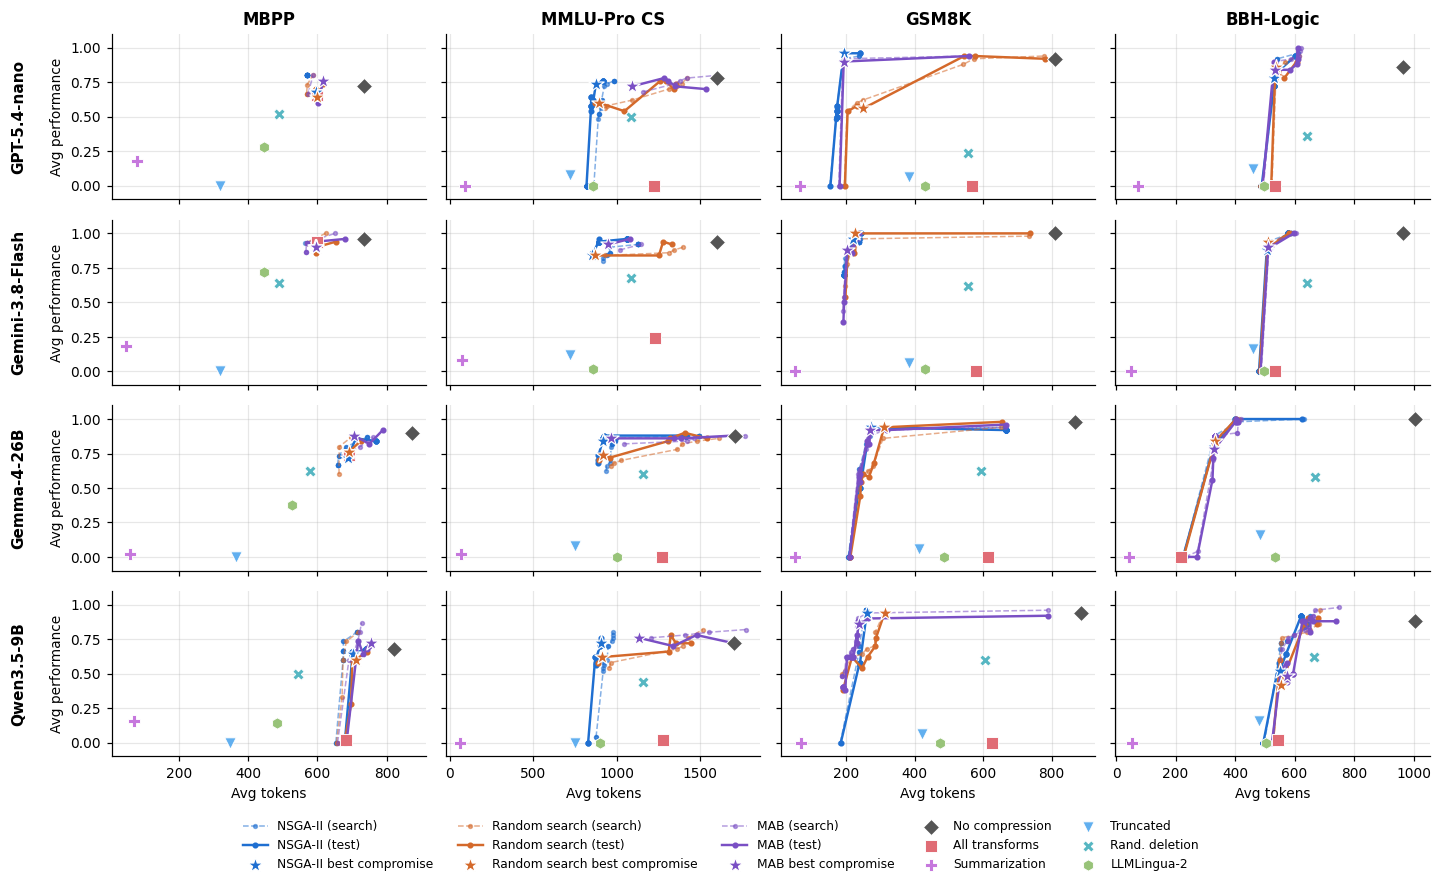

test - search performance of the compromise point (mean, mean |.|)
                     mean  <lambda_0>
method                               
multi_armed_bandit -0.027       0.065
nsga2              -0.040       0.060
random_search      -0.026       0.064
                              mean  <lambda_0>
task                                          
bbh_logical_deduction_nsga2 -0.100       0.110
gsm8k_cot_nsga2              0.010       0.033
mbpp_instruct_nsga2         -0.053       0.077
mmlu_pro_cs_nsga2            0.018       0.032
overall mean -0.031 mean abs 0.063



In [3]:
show("rq1_fronts")
print((NUM / "generalization.txt").read_text() if (NUM / "generalization.txt").exists() else "")

## RQ2 — Optimizers vs baselines
Best compromise (Table compromise), post-hoc tests (Table posthoc), hypervolume (Table hv), LLMLingua-2 at equal compression.

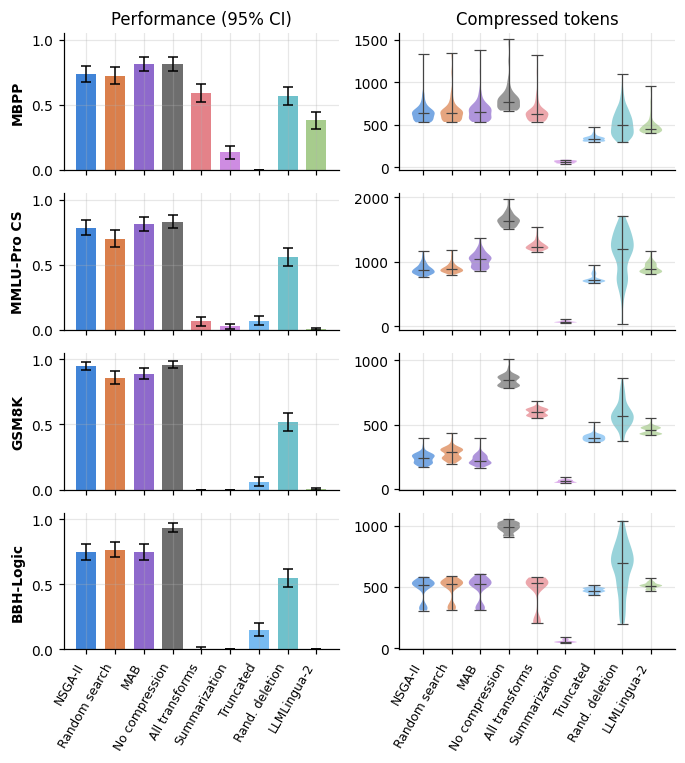

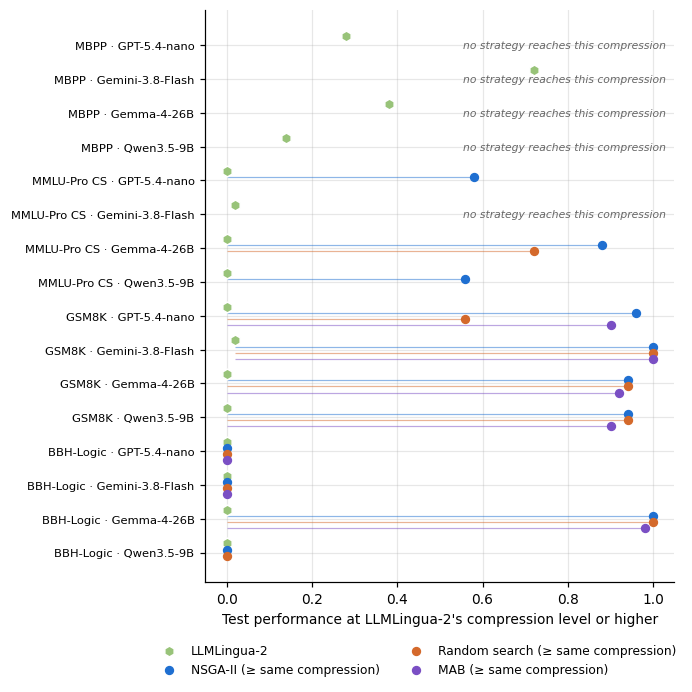

,metric,methods,cells,chi2,p,kendall_w
0,test_performance,9,16,104.457265,5.225684e-19,0.816072
1,compression,9,16,91.902032,1.910337e-16,0.717985
2,hv_search,3,16,3.375000,1.849814e-01,0.105469
3,hv_test,3,16,4.625000,9.901341e-02,0.144531


,method,cells_reaching_llmlingua_compression,cells_total,mean_performance,mean_llmlingua2_performance,mean_compression,mean_llmlingua2_compression,wins,ties,p_wilcoxon_greater,rank_biserial,p_holm
0,nsga2,11,16,0.623636,0.001818,0.574253,0.466223,8,3,0.003906,1.0,0.011719
1,random_search,9,16,0.573333,0.002222,0.582430,0.465732,6,3,0.015625,1.0,0.031250
2,multi_armed_bandit,7,16,0.671429,0.002857,0.626465,0.468677,5,2,0.031250,1.0,0.031250


In [4]:
show("rq2_distributions")
show("rq2_llmlingua_matched")
display(pd.read_csv(FIG / "rq2_friedman.csv"))
display(pd.read_csv(FIG / "rq2_llmlingua_matched_summary.csv"))

## RQ3 — Cost, break-even, convergence

nsga2: output tokens/request nc 369.5 vs compromise 529.6; saved output mean -160.0 (cells with longer outputs: 13/16); search O/I ratio 0.645
   rho=0: median 6787 q1 5782 q3 12066; never pays back in 0/16 cells
   rho=1: median 20176 q1 9468 q3 inf; never pays back in 4/16 cells
   rho=4: median 109622 q1 21866 q3 nan; never pays back in 6/16 cells
random_search: output tokens/request nc 369.5 vs compromise 559.8; saved output mean -190.3 (cells with longer outputs: 14/16); search O/I ratio 0.544
   rho=0: median 20793 q1 17453 q3 28312; never pays back in 0/16 cells
   rho=1: median 48660 q1 30019 q3 inf; never pays back in 4/16 cells
   rho=4: median inf q1 49678 q3 nan; never pays back in 8/16 cells
multi_armed_bandit: output tokens/request nc 369.5 vs compromise 459.1; saved output mean -89.5 (cells with longer outputs: 13/16); search O/I ratio 0.509
   rho=0: median 22054 q1 10515 q3 33790; never pays back in 0/16 cells
   rho=1: median 42492 q1 16368 q3 54870; never pays back i

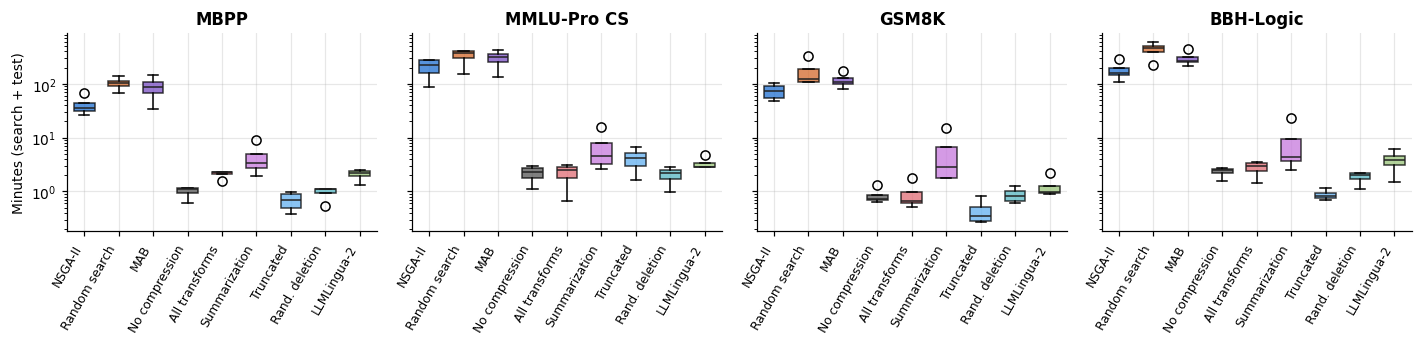

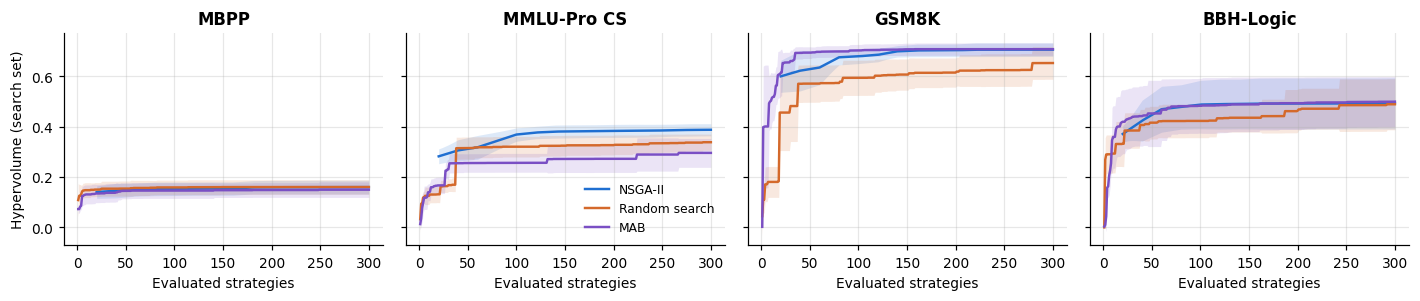

,method,search_calls,search_hours,search_hours_min,search_hours_max,search_input_Mtokens,saved_tokens,break_even_median,break_even_q1,break_even_q3,strategies_to_95pct_hv
0,multi_armed_bandit,9972.75,3.240443,0.490287,7.072333,9.401057,463.71500,22053.694906,10515.418499,33789.664688,42.5
1,nsga2,5893.75,1.992642,0.340208,4.734240,4.447757,505.80500,6786.651286,5781.853103,12066.437281,80.0
2,random_search,12307.50,4.202674,0.969815,9.699078,10.981122,491.50625,20793.376561,17453.132137,28312.042458,134.5


In [5]:
run("cost_extended.py")
show("rq3_timing")
show("rq3_convergence")
display(pd.read_csv(FIG / "rq3_cost_summary.csv"))

## RQ4 — Operators and transfer

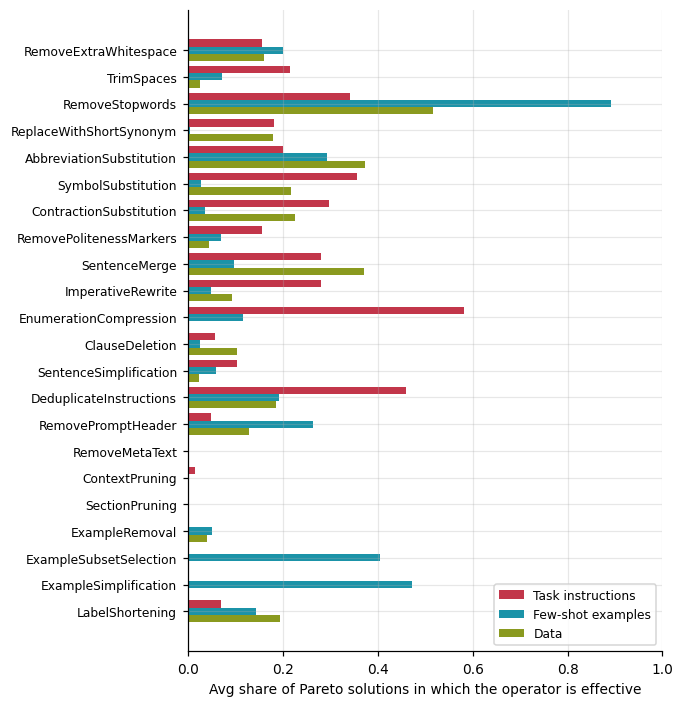

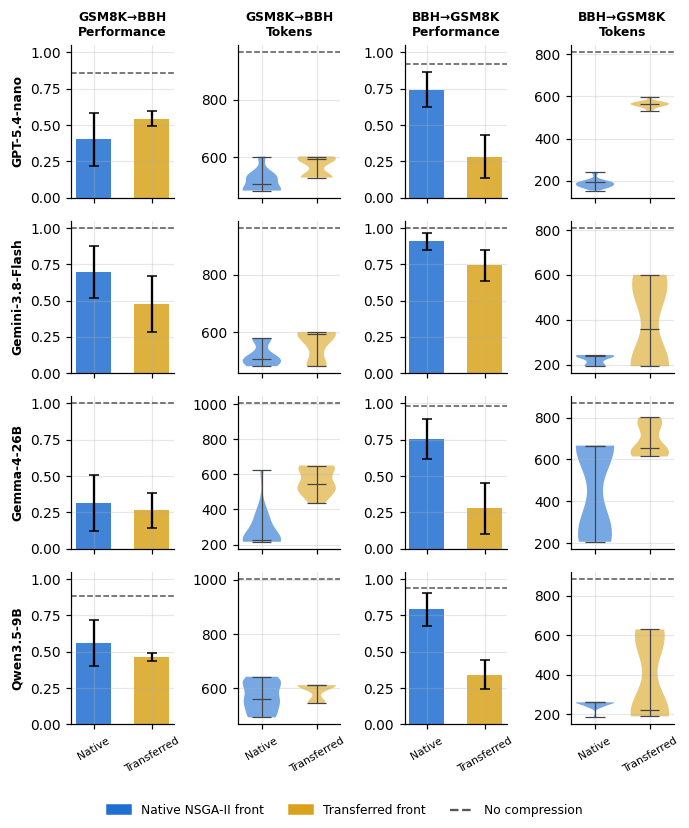

In [6]:
show("rq4_operators")
show("rq4_transfer")

## Tables (LaTeX) and numbers quoted in the text

In [7]:
run("make_tables.py")
for s in ("paper_numbers.py", "extra_numbers.py", "repeatability.py", "generalization.py"):
    run(s)

== compromise.tex
NSGA-II & 0.74 & 0.18 & 0.78 & 0.46 & 0.95 & 0.72 & 0.74 & 0.51 & 0.80 & 0.47 \\
Random Search & 0.73 & 0.18 & 0.70 & 0.46 & 0.86 & 0.68 & 0.76 & 0.51 & 0.76 & 0.45 \\
MAB & 0.81 & 0.15 & 0.81 & 0.37 & 0.89 & 0.73 & 0.75 & 0.50 & 0.82 & 0.44 \\
\midrule
No Compression & 0.82 & 0.00 & 0.83 & 0.00 & 0.96 & 0.00 & 0.93 & 0.00 & 0.89 & 0.00 \\
All Transf. & 0.59 & 0.19 & 0.07 & 0.24 & 0.00 & 0.29 & 0.01 & 0.53 & 0.17 & 0.31 \\
Summarization & 0.14 & 0.92 & 0.03 & 0.96 & 0.00 & 0.93 & 0.00 & 0.94 & 0.04 & 0.94 \\
Truncated Prompt & 0.00 & 0.57 & 0.07 & 0.55 & 0.06 & 0.53 & 0.15 & 0.52 & 0.07 & 0.54 \\
Random Deletion & 0.57 & 0.33 & 0.56 & 0.32 & 0.52 & 0.32 & 0.55 & 0.34 & 0.55 & 0.33 \\
LLMLingua-2 & 0.38 & 0.40 & 0.01 & 0.45 & 0.01 & 0.46 & 0.00 & 0.48 & 0.10 & 0.45 \\

== cost.tex
NSGA-II & 5.9k & 4.4M & 2.9M & 2.0 (0.3--4.7) & 506 & +160 & 6.8k (5.8--12.1k) & 20.2k (4/16) & 80 \\
Random Search & 12.3k & 11.0M & 6.0M & 4.2 (1.0--9.7) & 492 & +190 & 20.8k (17.5--28.3k) 

         D     I     S
operator                                  
RemoveExtraWhitespace     0.16  0.16  0.20
TrimSpaces                0.03  0.21  0.07
RemoveStopwords           0.52  0.34  0.89
ReplaceWithShortSynonym   0.18  0.18  0.01
AbbreviationSubstitution  0.37  0.20  0.29
SymbolSubstitution        0.22  0.36  0.03
ContractionSubstitution   0.22  0.30  0.04
RemovePolitenessMarkers   0.04  0.16  0.07
SentenceMerge             0.37  0.28  0.10
ImperativeRewrite         0.09  0.28  0.05
EnumerationCompression    0.00  0.58  0.12
ClauseDeletion            0.10  0.06  0.03
SentenceSimplification    0.02  0.10  0.06
DeduplicateInstructions   0.19  0.46  0.19
RemovePromptHeader        0.13  0.05  0.26
RemoveMetaText            0.00  0.00  0.00
ContextPruning            0.00  0.01  0.00
SectionPruning            0.00  0.00  0.00
ExampleRemoval            0.04  0.00  0.05
ExampleSubsetSelection    0.00  0.00  0.41
ExampleSimplification     0.00  0.00  0.47
LabelShortening           0.19 

ash           truncated_prompt          0/   365 = 0.000%
gemma4-26b-a4b-it          all_transformations       9/   365 = 2.466%
gemma4-26b-a4b-it          llmlingua2               10/   365 = 2.740%
gemma4-26b-a4b-it          multi_armed_bandit     1562/ 37299 = 4.188%
gemma4-26b-a4b-it          no_compression            5/   365 = 1.370%
gemma4-26b-a4b-it          nsga2                  1428/ 30334 = 4.708%
gemma4-26b-a4b-it          random_deletion           5/   365 = 1.370%
gemma4-26b-a4b-it          random_search          3211/ 50365 = 6.375%
gemma4-26b-a4b-it          summarization             6/   365 = 1.644%
gemma4-26b-a4b-it          truncated_prompt         17/   365 = 4.658%
gpt-5.4-nano-2026-03-17    all_transformations       0/   365 = 0.000%
gpt-5.4-nano-2026-03-17    llmlingua2                0/   365 = 0.000%
gpt-5.4-nano-2026-03-17    multi_armed_bandit        3/ 45640 = 0.007%
gpt-5.4-nano-2026-03-17    no_compression            0/   365 = 0.000%
gpt-5.4-nano-2026-0

gemini-3.8-flash           groups    885 pairs     885 same score 0.820 identical output 0.054
gemma4-26b-a4b-it          groups   1575 pairs    1649 same score 0.971 identical output 0.230
gpt-5.4-nano-2026-03-17    groups    366 pairs     384 same score 0.940 identical output 0.034
qwen3.5-9b                 groups    400 pairs     510 same score 0.871 identical output 0.059



test - search performance of the compromise point (mean, mean |.|)
                     mean  <lambda_0>
method                               
multi_armed_bandit -0.027       0.065
nsga2              -0.040       0.060
random_search      -0.026       0.064
                              mean  <lambda_0>
task                                          
bbh_logical_deduction_nsga2 -0.100       0.110
gsm8k_cot_nsga2              0.010       0.033
mbpp_instruct_nsga2         -0.053       0.077
mmlu_pro_cs_nsga2            0.018       0.032
overall mean -0.031 mean abs 0.063



## Independent checks
Compromise selection re-implemented (48/48 agreement), RQ2 statistics and hypervolumes recomputed, and every number in `main.tex` traced to an output.

In [8]:
for s in ("check_compromise.py", "check_rq2.py", "audit_numbers.py"):
    run(s)

agreement 48/48
issues: none



RQ2 numbers reproduced: True | hypervolume mismatches: 0

unmatched: []

